In [ ]:
from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from sklearn.model_selection import GroupKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from threadpoolctl import threadpool_limits

threadpool_limits(limits=2)

def show_table(frame,formats=None,index=False):
    formatters={column:pattern.format for column,pattern in (formats or {}).items()}
    display(HTML(frame.to_html(index=index,border=0,classes='swing-table',formatters=formatters,na_rep='—',escape=True)))

DATA_PATH = None
EXCLUDE_2023 = True
OUTER_FOLDS = 5
INNER_FOLDS = 3
RIDGE_ALPHAS = [1.0, 10.0, 100.0]
RANDOM_SEED = 42
BOOTSTRAPS = 500
EXPORT = False
OUTPUT_DIR = Path('swing_plus_outputs')
PLAYER = 'Aaron Judge'
PLAYER_YEAR = 2025
PLAYER_SIDE = None
RUN_SENSITIVITY = False
SENSITIVITY_CHANGES = {'bat_speed': 0}
COUNT_COLUMNS = {'contact_rate': 'contact_rate_swings', 'xwobacon': 'xwobacon_batted_balls'}
REFERENCE_KEYS = ['year']

candidates = [Path('Updated_Swing_Descriptive_Counts.csv'),
              Path('data/Updated_Swing_Descriptive_Counts.csv'),
              Path('upload/Updated_Swing_Descriptive_Counts.csv'),
              Path(r'C:\Users\brend\OneDrive - Stonehill College\pybaseball_local\Updated_Swing_Descriptive_Counts.csv'),
              Path(r'C:\Users\brend\Downloads\Updated_Swing_Descriptive_Counts.csv')]
if DATA_PATH is None:
    DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None or not Path(DATA_PATH).exists():
    raise FileNotFoundError('Set DATA_PATH to Updated_Swing_Descriptive_Counts.csv.')

display(HTML('<style>.swing-table{border-collapse:collapse;font-size:13px}.swing-table th{background:#eff6ff;color:#1e3a8a;text-align:left}.swing-table th,.swing-table td{padding:7px 12px;border-bottom:1px solid #e5e7eb}.swing-table tbody tr:nth-child(even){background:#f8fafc}</style><h2>cSwing+ &amp; dSwing+</h2><p>Same-season descriptive swing profiles. '
             '100 is the season reference mean; 10 points is one standard deviation. Foul tips count as whiffs.</p>'))

In [2]:
def clean_name(value):
    s = str(value).replace('’', "'").lower().strip()
    s = re.sub(r'\b(jr|sr|ii|iii|iv)\.?$', '', s)
    return re.sub(r'\s+', ' ', s.replace('.', '')).strip()

ALIASES = {'batter': 'name', 'stand': 'side', 'Contact_pct': 'contact_rate',
           'Contact%': 'contact_rate', 'xwOBAcon': 'xwobacon',
           'swing_path_tilt': 'tilt', 'swing_length': 'swing_len',
           'intercept_ball_minus_batter_pos_y_inches': 'contact_y',
           'intercept_ball_minus_batter_pos_x_inches': 'contact_x',
           'total_competitive_swings': 'competitive_swings'}
BASE_FEATURES = ['bat_speed', 'tilt', 'attack_angle', 'swing_len', 'contact_y',
                 'attack_direction', 'side_enc']

def prepare_data(raw):
    d = raw.copy()
    for old, new in ALIASES.items():
        if old in d and old != new:
            if new in d:
                raise ValueError(f'Conflicting columns: {old} and {new}.')
            d = d.rename(columns={old: new})
    required = ['year', 'name', 'side', 'contact_rate', 'xwobacon',
                'bat_speed', 'tilt', 'attack_angle', 'swing_len', 'contact_y', 'attack_direction']
    missing = sorted(set(required) - set(d))
    if missing:
        raise ValueError(f'Missing columns: {missing}')
    d['year'] = pd.to_numeric(d.year, errors='raise').astype(int)
    if d.name.isna().any() or d.name.astype(str).str.strip().eq('').any():
        raise ValueError('Every row needs a player name.')
    d['side'] = d.side.astype(str).str.upper().str.strip()
    if not d.side.isin(['L', 'R']).all():
        raise ValueError('side must contain actual L/R batting side, not switch-hitter S.')
    d['side_enc'] = d.side.map({'L': 0., 'R': 1.})
    d['player_key'] = d.name.map(clean_name)

    if 'batter_id' in d:
        if d.batter_id.isna().any():
            raise ValueError('batter_id has missing values.')
        d['player_key'] = d.batter_id.astype(str)
    if d.duplicated(['year', 'player_key', 'side']).any():
        raise ValueError('Duplicate player-year-side rows; resolve before modeling.')
    numeric = BASE_FEATURES + ['contact_rate', 'xwobacon']
    if 'contact_x' in d:
        numeric += ['contact_x']
    if 'competitive_swings' in d:
        numeric += ['competitive_swings']
    for count_col in COUNT_COLUMNS.values():
        if count_col is not None:
            if count_col not in d:
                raise ValueError(f'Configured count column absent: {count_col}')
            numeric += [count_col]
    for col in set(numeric):
        d[col] = pd.to_numeric(d[col], errors='coerce')
        if np.isinf(d[col]).any():
            raise ValueError(f'Infinite values in {col}.')
    contact = d.contact_rate.dropna()
    if not contact.between(0, 1).all():
        raise ValueError('Contact rate must be a fraction between 0 and 1; do not silently clip percentages.')
    if (d.xwobacon.dropna() < 0).any():
        raise ValueError('xwOBAcon must be nonnegative. Values above 1 are permitted.')
    for col in COUNT_COLUMNS.values():
        if col is not None and (d[col].isna().any() or (d[col] < 0).any() or (d[col] % 1 != 0).any()):
            raise ValueError(f'{col} must have nonnegative integer verified counts. Zero-count targets are excluded individually.')
    if EXCLUDE_2023:
        d = d[d.year != 2023].copy()
    observed = [c for c in BASE_FEATURES if c != 'side_enc']
    d['tracking_available'] = d[observed].notna().any(axis=1)
    if (d.swing_len.dropna() <= 0).any():
        raise ValueError('Swing length must be positive.')
    return d.reset_index(drop=True)


raw = pd.read_csv(DATA_PATH)
required_counts = ['contact_rate_swings','contact_events','whiff_events','foul_tip_events',
                   'xwobacon_batted_balls','xwobacon_sum','Contact_pct','xwOBAcon','data_schema']
missing = sorted(set(required_counts)-set(raw.columns))
if missing:
    raise ValueError(f'Missing audited data columns: {missing}')
if not raw.data_schema.eq('descriptive_counts_v1').all():
    raise ValueError('Use the descriptive_counts_v1 builder output.')
if 'contact_definition' not in raw or not raw.contact_definition.str.contains('foul_tip is a whiff',regex=False).all():
    raise ValueError('Contact definition must treat foul tips as whiffs.')
for target_col,count_col,sum_col in [('Contact_pct','contact_rate_swings','contact_events'),
                                     ('xwOBAcon','xwobacon_batted_balls','xwobacon_sum')]:
    valid = raw[count_col].gt(0)
    np.testing.assert_allclose(raw.loc[valid,target_col],
        raw.loc[valid,sum_col]/raw.loc[valid,count_col],atol=1e-10)
    if raw.loc[~valid,target_col].notna().any():
        raise ValueError('A target with zero denominator must be missing.')
if not (raw.contact_events+raw.whiff_events==raw.contact_rate_swings).all():
    raise ValueError('Contact and whiff counts do not reconstruct total swings.')
if not (raw.foul_tip_events<=raw.whiff_events).all():
    raise ValueError('Foul tips exceed recorded whiffs.')
df = prepare_data(raw)
feature_columns = BASE_FEATURES + (['contact_x'] if 'contact_x' in df else [])
data_summary = df.groupby('year').agg(players=('player_key','nunique'),
                                     rows=('name','size'),tracked_rows=('tracking_available','sum'))
display(data_summary.rename(columns={'players':'Players','rows':'Batting-side rows',
                                    'tracked_rows':'Rows with tracking'}))

,Players,Batting-side rows,Rows with tracking
year,,,
2024,482,512,512
2025,482,514,514
2026,490,522,522


In [3]:
def make_model(alpha):
    return Pipeline([('imputer',SimpleImputer(strategy='median',keep_empty_features=True)),
                     ('scaler',StandardScaler()),('ridge',Ridge(alpha=alpha))])

def bounded_prediction(prediction,target):
    return np.clip(prediction,0.0,1.0) if target=='contact_rate' else np.maximum(prediction,0.0)

def loss_metrics(observed,predicted,weights=None):
    return {'RMSE':float(np.sqrt(mean_squared_error(observed,predicted,sample_weight=weights))),
            'MAE':float(mean_absolute_error(observed,predicted,sample_weight=weights)),
            'R²':float(r2_score(observed,predicted,sample_weight=weights)),
            'Bias':float(np.average(np.asarray(predicted)-np.asarray(observed),weights=weights))}

def select_alpha(x,y,groups,target):
    splits=list(GroupKFold(n_splits=INNER_FOLDS).split(x,y,groups))
    trials=[]
    for alpha in RIDGE_ALPHAS:
        prediction=np.full(len(y),np.nan)
        for train,validation in splits:
            assert set(groups.iloc[train]).isdisjoint(set(groups.iloc[validation]))
            model=make_model(alpha)
            model.fit(x.iloc[train],y.iloc[train])
            prediction[validation]=bounded_prediction(model.predict(x.iloc[validation]),target)
        trials.append({'alpha':alpha,'inner_rmse':np.sqrt(mean_squared_error(y,prediction))})
    table=pd.DataFrame(trials)
    return float(table.loc[table.inner_rmse.idxmin(),'alpha']),table

def feature_contributions(model,x):
    values=model[:-1].transform(x)*model['ridge'].coef_
    base=np.full(len(x),model['ridge'].intercept_)
    np.testing.assert_allclose(base+values.sum(axis=1),model.predict(x),atol=1e-8)
    return pd.DataFrame(values,index=x.index,columns=feature_columns),base

def fit_model(data,target):
    eligible=data.tracking_available & data[target].notna() & data[COUNT_COLUMNS[target]].gt(0)
    frame=data.loc[eligible].copy()
    frame['source_row']=frame.index
    frame=frame.reset_index(drop=True)
    x,y,groups=frame[feature_columns],frame[target],frame.player_key
    prediction=np.full(len(frame),np.nan)
    baseline=np.full(len(frame),np.nan)
    contributions=pd.DataFrame(0.0,index=frame.index,columns=feature_columns)
    bases=np.full(len(frame),np.nan)
    folds=np.zeros(len(frame),dtype=int)
    fold_records,selection_records=[],[]
    for fold,(train,test) in enumerate(GroupKFold(n_splits=OUTER_FOLDS).split(x,y,groups),1):
        assert set(groups.iloc[train]).isdisjoint(set(groups.iloc[test]))
        alpha,trials=select_alpha(x.iloc[train].reset_index(drop=True),
                                  y.iloc[train].reset_index(drop=True),
                                  groups.iloc[train].reset_index(drop=True),target)
        trials['target'],trials['outer_fold']=target,fold
        selection_records.append(trials)
        model=make_model(alpha)
        model.fit(x.iloc[train],y.iloc[train])
        prediction[test]=bounded_prediction(model.predict(x.iloc[test]),target)
        values,base=feature_contributions(model,x.iloc[test])
        contributions.loc[test,:],bases[test]=values.to_numpy(),base
        means=frame.iloc[train].groupby('year')[target].mean()
        baseline[test]=frame.iloc[test].year.map(means).fillna(y.iloc[train].mean())
        folds[test]=fold
        fold_records.append({'Target':target,'Fold':fold,'Alpha':alpha,
                             'Training players':groups.iloc[train].nunique(),
                             'Test players':groups.iloc[test].nunique(),
                             **loss_metrics(y.iloc[test],prediction[test])})
    assert np.isfinite(prediction).all() and np.isfinite(baseline).all()
    alpha,trials=select_alpha(x,y,groups,target)
    trials['target'],trials['outer_fold']=target,'full_fit'
    selection_records.append(trials)
    model=make_model(alpha)
    model.fit(x,y)
    frame['estimate']=prediction
    frame['season_baseline']=baseline
    frame['fitted_estimate']=bounded_prediction(model.predict(x),target)
    frame['fold']=folds
    metrics=[]
    counts=frame[COUNT_COLUMNS[target]].to_numpy(dtype=float)
    for label,pred in [('Ridge',prediction),('Season mean',baseline)]:
        for name,weights in [('Player rows',None),('Target counts',counts)]:
            metrics.append({'Target':target,'Model':label,'Evaluation':name,**loss_metrics(y,pred,weights)})
    return {'target':target,'data':frame,'model':model,'alpha':alpha,
            'metrics':pd.DataFrame(metrics),'folds':pd.DataFrame(fold_records),
            'selection':pd.concat(selection_records,ignore_index=True),
            'contributions':contributions,'base':bases}

results={target:fit_model(df,target) for target in ['contact_rate','xwobacon']}
validation=pd.concat([r['metrics'] for r in results.values()],ignore_index=True)
target_labels={'contact_rate':'cSwing+','xwobacon':'dSwing+'}
validation['Target']=validation.Target.map(target_labels)
display(HTML('<h3>Validation</h3>'))
show_table(validation,{'RMSE':'{:.5f}','MAE':'{:.5f}','R²':'{:.3f}','Bias':'{:+.5f}'})

Target,Model,Evaluation,RMSE,MAE,R²,Bias
cSwing+,Ridge,Player rows,0.04953,0.03934,0.427,+0.00007
cSwing+,Ridge,Target counts,0.04654,0.03706,0.449,-0.00793
cSwing+,Season mean,Player rows,0.06555,0.05265,-0.004,-0.00001
cSwing+,Season mean,Target counts,0.06293,0.05042,-0.007,-0.00381
dSwing+,Ridge,Player rows,0.03690,0.02820,0.547,-0.00005
dSwing+,Ridge,Target counts,0.03419,0.02579,0.596,-0.00623
dSwing+,Season mean,Player rows,0.05473,0.04358,0.002,+0.00001
dSwing+,Season mean,Target counts,0.05426,0.04271,-0.018,-0.00763


Player,Side,cSwing+,dSwing+
Spencer Jones,L,77.0,132.2
Nick Kurtz,L,77.6,132.1
Riley Greene,L,82.4,129.9
James Wood,L,87.2,122.5
Garrett Mitchell,L,86.9,122.5
Giancarlo Stanton,R,74.0,120.4
Kyle Stowers,L,81.4,120.2
Brett Baty,L,87.2,120.1
Munetaka Murakami,L,78.3,119.8
Zach Dezenzo,R,84.6,119.7


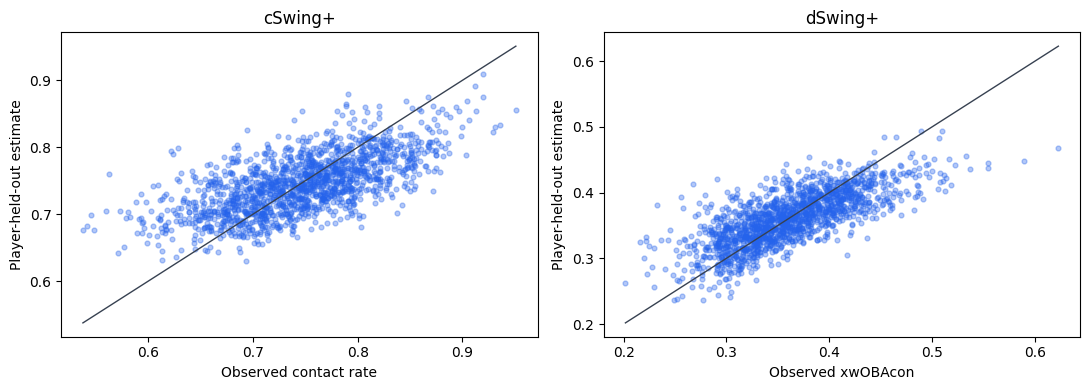

In [4]:
references={}
scores=df[['year','name','side','player_key','tracking_available']].copy()
for target,label in target_labels.items():
    frame=results[target]['data']
    reference=frame.groupby('year').estimate.agg(['mean','std','size']).reset_index()
    if (reference['std'].fillna(0)<1e-8).any():
        raise ValueError('Insufficient score variation within a season.')
    references[target]=reference
    scored=frame.merge(reference,on='year',validate='many_to_one').set_index('source_row')
    scores[label]=100+10*(scored.estimate-scored['mean'])/scored['std']
    scores[label+'_fitted']=100+10*(scored.fitted_estimate-scored['mean'])/scored['std']
    scores[target+'_estimate']=scored.estimate
    scores[target+'_fitted']=scored.fitted_estimate
    scores[target+'_fold']=scored.fold
    scores[target+'_observed']=scored[target]

DISPLAY_YEAR=int(scores.year.max())
leaderboard=scores[scores.year.eq(DISPLAY_YEAR)].dropna(subset=['cSwing+','dSwing+'])
leaderboard=leaderboard[['name','side','cSwing+','dSwing+']].sort_values('dSwing+',ascending=False)
display(HTML(f'<h3>{DISPLAY_YEAR} swing profiles</h3>'))
show_table(leaderboard.head(20).rename(columns={'name':'Player','side':'Side'}),
           {'cSwing+':'{:.1f}','dSwing+':'{:.1f}'})
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,(target,result) in zip(axes,results.items()):
    frame=result['data']
    ax.scatter(frame[target],frame.estimate,s=12,alpha=.35,color='#2563eb')
    lower=min(frame[target].min(),frame.estimate.min())
    upper=max(frame[target].max(),frame.estimate.max())
    ax.plot([lower,upper],[lower,upper],color='#374151',lw=1)
    ax.set(title=target_labels[target],xlabel='Observed contact rate' if target=='contact_rate' else 'Observed xwOBAcon',
           ylabel='Player-held-out estimate')
plt.tight_layout()
plt.show()

In [5]:
def paired_bootstrap(result):
    frame=result['data']
    summary=pd.DataFrame({'player':frame.player_key,
                         'model_error':(frame.estimate-frame[result['target']])**2,
                         'baseline_error':(frame.season_baseline-frame[result['target']])**2}).groupby('player').agg(
                         model_error=('model_error','sum'),baseline_error=('baseline_error','sum'),
                         rows=('model_error','size')).reset_index(drop=True)
    rng=np.random.default_rng(RANDOM_SEED)
    differences=[]
    for _ in range(BOOTSTRAPS):
        sample=summary.iloc[rng.integers(0,len(summary),len(summary))]
        differences.append(np.sqrt(sample.model_error.sum()/sample.rows.sum())-
                           np.sqrt(sample.baseline_error.sum()/sample.rows.sum()))
    return {'Target':target_labels[result['target']],
            'RMSE difference':np.sqrt(summary.model_error.sum()/summary.rows.sum())-
                              np.sqrt(summary.baseline_error.sum()/summary.rows.sum()),
            '95% lower':np.quantile(differences,.025),'95% upper':np.quantile(differences,.975)}
bootstrap=pd.DataFrame([paired_bootstrap(result) for result in results.values()])
diagnostic_records=[]
for target,result in results.items():
    frame=result['data'].copy()
    count_column=COUNT_COLUMNS[target]
    bins=[0,150,300,600,1000,np.inf] if target=='contact_rate' else [0,50,100,200,400,np.inf]
    frame['sample_bin']=pd.cut(frame[count_column],bins=bins)
    for sample,part in frame.groupby('sample_bin',observed=True):
        diagnostic_records.append({'Target':target_labels[target],'Sample':str(sample),'Rows':len(part),
                                   **loss_metrics(part[target],part.estimate)})
diagnostics=pd.DataFrame(diagnostic_records)

Player,Season,Side,cSwing+,dSwing+
Aaron Judge,2025,R,77.1,122.0


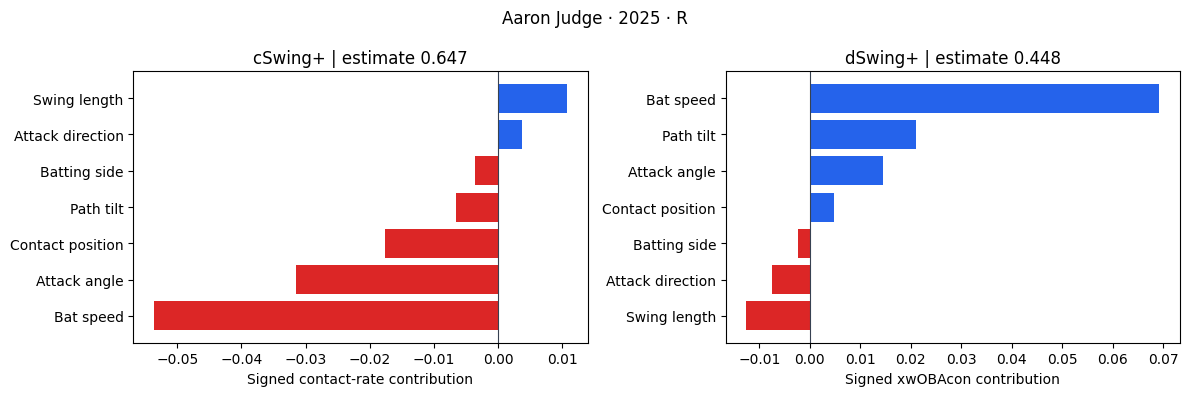

In [6]:
def find_player(player,year,side=None):
    if isinstance(player,(int,np.integer)):
        mask=df.player_key.eq(str(player))
    else:
        mask=df.name.map(clean_name).eq(clean_name(player))
    mask &= df.year.eq(int(year))
    if side is not None:
        mask &= df.side.eq(str(side).upper())
    matches=df.index[mask].tolist()
    if not matches:
        raise ValueError('Player/year/side not found. A numeric MLBAM ID can also be used.')
    return matches

def player_profile(player,year,side=None):
    rows=find_player(player,year,side)
    show_table(scores.loc[rows,['name','year','side','cSwing+','dSwing+']].rename(
        columns={'name':'Player','year':'Season','side':'Side'}),{'cSwing+':'{:.1f}','dSwing+':'{:.1f}'})
    groups={'Bat speed':['bat_speed'],'Path tilt':['tilt'],'Attack angle':['attack_angle'],
            'Swing length':['swing_len'],'Contact position':['contact_x','contact_y'],
            'Attack direction':['attack_direction'],'Batting side':['side_enc']}
    for source_row in rows:
        fig,axes=plt.subplots(1,2,figsize=(12,4))
        for ax,(target,result) in zip(axes,results.items()):
            match=result['data'].index[result['data'].source_row.eq(source_row)]
            if not len(match):
                ax.set_visible(False)
                continue
            position=match[0]
            values=result['contributions'].loc[position]
            grouped=pd.Series({name:values.reindex(columns,fill_value=0).sum() for name,columns in groups.items()})
            np.testing.assert_allclose(grouped.sum(),values.sum(),atol=1e-8)
            predicted=bounded_prediction(np.array([result['base'][position]+grouped.sum()]),target)[0]
            np.testing.assert_allclose(predicted,result['data'].loc[position,'estimate'],atol=1e-8)
            ordered=grouped.sort_values()
            ax.barh(ordered.index,ordered.values,color=np.where(ordered.values>=0,'#2563eb','#dc2626'))
            ax.axvline(0,color='#374151',lw=.8)
            ax.set(title=f'{target_labels[target]} | estimate {predicted:.3f}',
                   xlabel='Signed contact-rate contribution' if target=='contact_rate' else 'Signed xwOBAcon contribution')
        fig.suptitle(f'{df.loc[source_row,"name"]} · {year} · {df.loc[source_row,"side"]}')
        plt.tight_layout()
        plt.show()

def reference_score(estimate,row,target):
    reference=references[target].loc[references[target].year.eq(int(row.year))]
    if len(reference)!=1:
        raise ValueError('No unique season score reference.')
    return 100+10*(estimate-reference.iloc[0]['mean'])/reference.iloc[0]['std']

def simulate_swing_change(player,year,tweaks,side=None):
    allowed=set(feature_columns)-{'side_enc'}
    if set(tweaks)-allowed:
        raise ValueError(f'Changes must use raw mechanical inputs: {sorted(allowed)}')
    report=[]
    for source_row in find_player(player,year,side):
        base=df.loc[[source_row]].copy()
        changed=base.copy()
        for feature,change in tweaks.items():
            if not np.isfinite(float(change)) or base[feature].isna().any():
                raise ValueError(f'Invalid change or missing measurement: {feature}')
            changed[feature]+=float(change)
            minimum,maximum=df.loc[df.tracking_available,feature].agg(['min','max'])
            if not changed[feature].between(minimum,maximum).all():
                warnings.warn(f'{feature} is outside the observed range.')
        if changed.swing_len.iloc[0]<=0:
            raise ValueError('Swing length must remain positive.')
        for target,label in target_labels.items():
            model=results[target]['model']
            before=bounded_prediction(model.predict(base[feature_columns]),target)[0]
            after=bounded_prediction(model.predict(changed[feature_columns]),target)[0]
            report.append({'Player':base.name.iloc[0],'Season':year,'Side':base.side.iloc[0],
                           'Metric':label,'Before':before,'After':after,'Change':after-before,
                           'Score before':reference_score(before,base.iloc[0],target),
                           'Score after':reference_score(after,base.iloc[0],target)})
    report=pd.DataFrame(report)
    display(HTML('<h3>Hypothetical model response</h3><p>Full-fit estimates; changes are not causal effects.</p>'))
    show_table(report,{c:'{:.4f}' for c in ['Before','After','Change','Score before','Score after']})
    return report

player_profile(PLAYER,PLAYER_YEAR,PLAYER_SIDE)
if RUN_SENSITIVITY:
    simulate_swing_change(PLAYER,PLAYER_YEAR,SENSITIVITY_CHANGES,PLAYER_SIDE)

In [7]:
if EXPORT:
    import joblib
    OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
    scores.to_csv(OUTPUT_DIR/'swing_plus_scores.csv',index=False)
    validation.to_csv(OUTPUT_DIR/'validation.csv',index=False)
    bootstrap.to_csv(OUTPUT_DIR/'bootstrap_vs_season_mean.csv',index=False)
    diagnostics.to_csv(OUTPUT_DIR/'sample_diagnostics.csv',index=False)
    for target,result in results.items():
        result['folds'].to_csv(OUTPUT_DIR/f'{target}_folds.csv',index=False)
        result['selection'].to_csv(OUTPUT_DIR/f'{target}_selection.csv',index=False)
        contributions=result['data'][['year','name','side','player_key','source_row','fold']].join(result['contributions'])
        contributions['base_value']=result['base']
        contributions['units']=target
        contributions.to_csv(OUTPUT_DIR/f'{target}_contributions.csv',index=False)
    bundle={'models':{target:result['model'] for target,result in results.items()},
            'alphas':{target:result['alpha'] for target,result in results.items()},
            'features':feature_columns,'references':references,'reference_keys':REFERENCE_KEYS,
            'count_columns':COUNT_COLUMNS,'exclude_2023':EXCLUDE_2023,
            'purpose':'same-season descriptive swing associations',
            'contact_definition':'foul tips count as whiffs'}
    joblib.dump(bundle,OUTPUT_DIR/'swing_plus_models.joblib')
    print('Saved to',OUTPUT_DIR.resolve())